# 03 · Creación de variables (feature engineering)

> **Flujo del proyecto** (diagrama del profesor)
> `01 Limpieza` → `02 Exploración` → `03 Creación de variables` → `04 Preparación (split temporal + folds)` →
> `05a Logística` · `05b Random Forest` · `05c XGBoost` · `05d Red neuronal` (cada uno: selección de variables → hiperparámetros) →
> `06 Selección del mejor modelo y prueba final en test`


    **Entrada:** `datos/interim/` · **Salida:** `datos/processed/dataset_pedidos.parquet` (una fila por pedido).

    **Principio:** sólo información disponible **al momento de la compra**. Las variables históricas son *point-in-time*:
    para un pedido comprado en el instante *t* sólo se cuentan labels que la empresa ya conocía antes de *t*
    (`label_conocida_en < t`). Por eso no dependen del corte train/test y se pueden crear antes del split sin fuga.

    **Cambio respecto a la versión anterior:** el suavizado de las tasas usaba la tasa global de **todo** el periodo de
    entrenamiento, lo que filtraba información futura hacia los primeros folds. Ahora el *prior* es la tasa global conocida
    hasta la fecha de cada compra.

In [1]:
import sys, json, time, warnings
from pathlib import Path

RAIZ = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(RAIZ))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

from src import config, viz
viz.aplicar_estilo()
pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 200)

from src import features as F

In [2]:
t = {n: pd.read_parquet(config.DATOS_INTERIM / f"{n}.parquet")
     for n in ["orders", "customers", "sellers", "items", "products", "payments", "geolocation"]}
orders_raw = pd.read_csv(config.DATOS_RAW / "olist_orders_dataset.csv", usecols=["order_purchase_timestamp"])

t0 = time.time()
df_completo = F.construir_dataset(t, orders_raw)        # incluye 2016 (sirve como historial)
df = df_completo[df_completo["order_purchase_timestamp"] >= config.FECHA_INICIO_MODELO].reset_index(drop=True)
print(f"Dataset: {df.shape[0]:,} pedidos x {df.shape[1]} columnas ({time.time() - t0:.1f} s)")

Dataset: 96,201 pedidos x 44 columnas (4.1 s)


### Diccionario de variables

| Grupo | Variables | Qué capturan |
|---|---|---|
| Promesa de entrega | `estimated_delivery_days`, `avg/min_dias_limite_envio` | Plazo prometido al cliente y plazo del vendedor para despachar |
| Pedido | `total_items`, `total_products`, `total_sellers`, `total_price`, `total_freight`, `freight_ratio`, `unique_product_categories` | Tamaño y complejidad del pedido |
| Producto | `avg/max_product_weight`, `avg_product_length/height/width`, `main_category` | Volumen y tipo de producto |
| Pago | `total_payment`, `max_installments`, `payment_types`, `main_payment_type` | Forma de pago |
| Geografía | `customer_state`, `seller_state`, `same_state`, `n_seller_states`, `avg/max_distance_km` | Ruta y distancia (Haversine) |
| Calendario | `purchase_weekday`, `franja_horaria` | Día y franja de compra (el mes **no** se usa: memoriza episodios) |
| Historial | `seller_late_rate`, `seller_n_prev`, `ruta_late_rate`, `ruta_n_prev` | Retrasos previos del vendedor y de la ruta (suavizados, m = 20) |
| Carga reciente | `global_late_30d`, `global_n_30d`, `estado_late_30d`, `pedidos_ult_7d` | Qué tan saturado está el sistema en los días previos a la compra |

### Verificación de no-fuga
Recalculamos por fuerza bruta, para 300 pedidos al azar, cuántos pedidos previos del mismo vendedor tenían label conocido
antes de la compra, y lo comparamos con `seller_n_prev`.

In [3]:
rng = np.random.default_rng(config.RANDOM_STATE)
muestra = df.sample(300, random_state=config.RANDOM_STATE)
errores = 0
for _, fila in muestra.iterrows():
    mismo = df_completo["main_seller_id"] == fila["main_seller_id"]
    conocidos = (df_completo["label_conocida_en"] < fila["order_purchase_timestamp"]) & mismo
    errores += int(conocidos.sum() != fila["seller_n_prev"])
print("Pedidos con conteo distinto:", errores)
assert errores == 0

Pedidos con conteo distinto: 0


### Carga reciente: lo que el modelo sabe al momento de comprar
`global_late_30d` sólo usa labels ya conocidos; por eso va "atrasada" respecto a la tasa real, pero anticipa las oleadas.

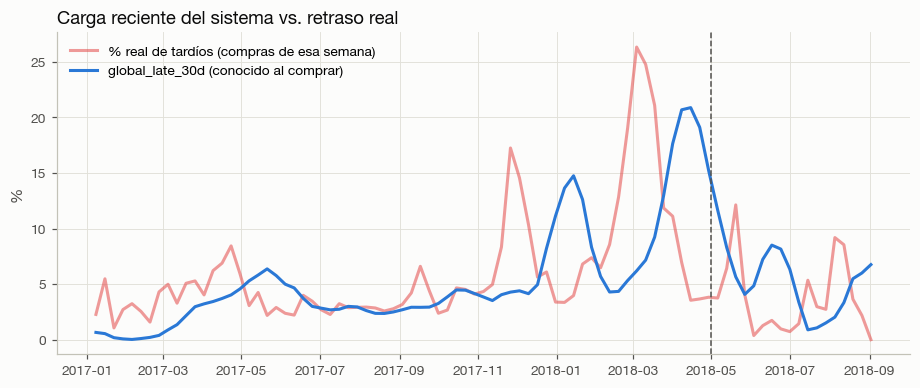

In [4]:
semanal = df.set_index("order_purchase_timestamp")[["global_late_30d", "delivery_late"]].resample("W").mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(semanal.index, semanal["delivery_late"], color=viz.TARDIO, alpha=0.55, label="% real de tardíos (compras de esa semana)")
ax.plot(semanal.index, semanal["global_late_30d"], color=viz.A_TIEMPO, label="global_late_30d (conocido al comprar)")
ax.axvline(pd.Timestamp(config.FECHA_CORTE_TEST), color=viz.TINTA_2, linestyle="--", linewidth=1)
ax.set_ylabel("%"); ax.set_title("Carga reciente del sistema vs. retraso real"); ax.legend(loc="upper left")
viz.guardar(fig, "fe_carga_reciente"); plt.show()

In [5]:
faltantes = df.isna().mean().mul(100).round(3)
display(faltantes[faltantes > 0].to_frame("% faltante (se imputa dentro de cada fold)"))
display(df.describe().T.round(3))
df.to_parquet(config.DATOS_PROCESSED / "dataset_pedidos.parquet", index=False)
print("Guardado:", config.DATOS_PROCESSED / "dataset_pedidos.parquet")

,% faltante (se imputa dentro de cada fold)
avg_product_weight,0.023
max_product_weight,0.023
avg_product_length,0.017
avg_product_height,0.017
avg_product_width,0.017
avg_distance_km,0.496
max_distance_km,0.496


,count,mean,min,25%,50%,75%,max,std
order_purchase_timestamp,96201,2018-01-03 05:15:51.271961856,2017-01-05 11:56:06,2017-09-15 12:57:46,2018-01-21 15:47:33,2018-05-06 02:04:47,2018-08-29 15:00:37,NaN
label_conocida_en,96201,2018-01-15 01:24:19.364985600,2017-01-11 13:14:05,2017-09-26 20:51:36,2018-02-02 21:08:40,2018-05-15 21:32:45,2018-08-31 07:31:51,NaN
delivery_late,96201.0,0.067889,0.0,0.0,0.0,0.0,1.0,0.251557
estimated_delivery_days,96201.0,23.647415,2.008009,18.318877,23.215266,28.374479,155.135463,8.601523
total_items,96201.0,1.142088,1.0,1.0,1.0,1.0,21.0,0.538466
total_products,96201.0,1.038503,1.0,1.0,1.0,1.0,8.0,0.227556
total_sellers,96201.0,1.013908,1.0,1.0,1.0,1.0,5.0,0.123589
total_price,96201.0,136.993213,0.85,45.9,86.5,149.9,13440.0,209.110168
total_freight,96201.0,22.784793,0.0,13.85,17.17,24.01,1794.96,21.566308
avg_product_weight,96179.0,2097.984374,2.0,300.0,700.0,1800.0,40425.0,3744.79847


Guardado: /Users/fabiolajrz/Documents/proyecto_final_equipo_3/datos/processed/dataset_pedidos.parquet
